Imports:

In [1]:
import numpy as np
import skfuzzy as fuzz
from skfuzzy import control as ctrl

Energy Level: Users can select their energy level as one of five possible answers: *drained, tired, okay, good,* and *buzzing*. The energy levels are fuzzy and membership is shown as standard gaussian distributions. Events are classified with a recommended energy level between 1 and 5. The slope of the gaussian curves is dependent on the importance level.

To show how all the slopes overlap (change importance to see slope changes):

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/skfuzzy/control/fuzzyvariable.py:125: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


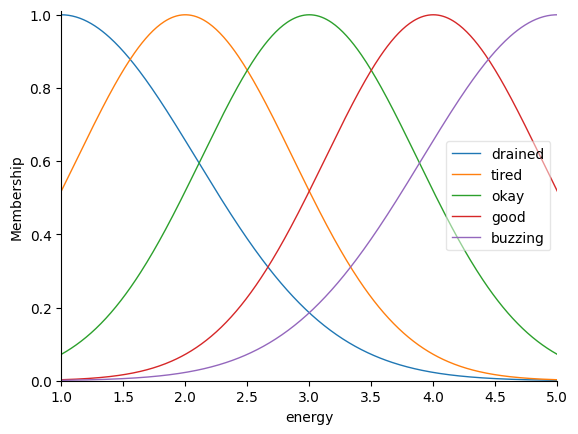

In [2]:
# energy is a scale of 1 to 5. When an event is posted, they assign an energy level within the range
energy = ctrl.Antecedent(np.linspace(1, 5, 401), 'energy')
relevance = ctrl.Consequent(np.arange(0, 26, 1), 'relevance')

# defines the fuzzy mappings
CENTERS = {'drained': 1, 'tired': 2, 'okay': 3, 'good': 4, 'buzzing': 5}

# importance bar 0-10. would be a slider bar in a UI
importance = 5  # when connecting to UI, connect to slider here!

def sigma_for_importance(imp):
    # slopes: 0 -> flat, 1->~1.09, 5->~0.87, 7->~0.76, 9->~0.65, 10->0.30 (no overlap)
    if imp <= 0:
        return None
    if imp >= 10:
        return 0.30
    if imp >= 9:
        return 0.65 - 0.35 * (imp - 9)
    return 1.15 - 0.0556 * imp

def apply_importance(imp):
    s = sigma_for_importance(imp)
    if s is None:
        # flat line at 1.0 -> 1 for any level (no effect on event order)
        flat = np.ones_like(energy.universe)
        for name in CENTERS:
            energy[name] = flat
    else:
        for name, c in CENTERS.items():
            # edges are a little wider so the peaks are centered right
            sigma = s * 1.25 if name in ('drained', 'buzzing') else s
            energy[name] = fuzz.gaussmf(energy.universe, c, sigma)

apply_importance(importance)
energy.view()


To actually implement the energy:

In [3]:
# Connect to UI here!
def getImportance(user_energy, importance, event_energy):
    apply_importance(importance)

    event_mu = fuzz.interp_membership(energy.universe, energy[user_energy].mf, event_energy)

    return round(event_mu, 3)


# Example:
user_label = "good"  # User input: drained, tired, okay, good, or buzzing
importance = 7       # Importance slider: 0-10
event_energy = 5     # Event's recommended energy level: 1-5

result = getImportance(user_label, importance, event_energy)

print(f"User energy: '{user_label}' (center {CENTERS[user_label]}) with importance {importance}")
print(f"Event energy: {event_energy}")
print(f"Event membership in user's '{user_label}': {result:.3f}")


User energy: 'good' (center 4) with importance 7
Event energy: 5
Event membership in user's 'good': 0.422


Time: can be *early evening*, *evening*, *night*, shows as overlapping trapezoids (trapezoids instead of gaussian curves so that for every time, there is a classification that is 100% relevant). In UI, implemented as a checklist where users can select multiple. 

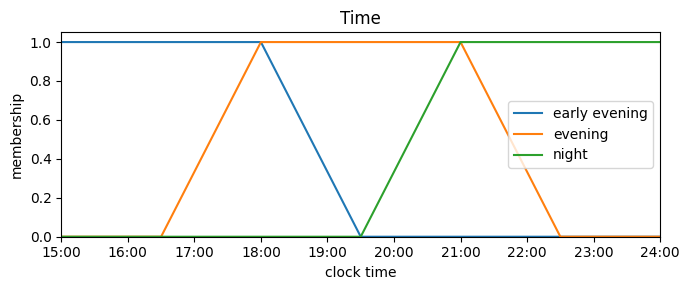

example: 17:00 -> {'early evening': 1.0, 'evening': 0.3333333333333333, 'night': 0.0}


In [4]:
import matplotlib.pyplot as plt

T = np.linspace(15, 24, 901)  # events can start between 15:00 and 24:00

def trap(a, b, c, d, x=T):    #create trapezoid function
    """Trapezoid: rises a->b, flat b->c, falls c->d (a<=b<=c<=d)."""
    up = (x >= a).astype(float) if b == a else (x - a) / (b - a)
    down = (x <= d).astype(float) if d == c else (d - x) / (d - c)
    return np.clip(np.minimum(up, down), 0, 1)

# the actual time values and defines the trap curves:
TIME_SETS = {     #15-24 9hr, 3hr each category. 15-18h is early, 18-21 is eve, 21-24 is night 
    'early evening': trap(15, 15, 18, 19.5),
    'evening':       trap(16.5, 18, 21, 22.5),
    'night':         trap(19.5, 21, 24, 24),
}
# create the actual graph:
fig, ax = plt.subplots(figsize=(7, 3)) 
for name, mf in TIME_SETS.items():
    ax.plot(T, mf, label=name)
ax.legend()
ax.set_xlim(15, 24)
ax.set_ylim(0, 1.05)
ax.set_xlabel("clock time")
ax.set_ylabel("membership")
ax.set_xticks([15, 16, 17, 18, 19, 20, 21, 22, 23, 24], ["15:00", "16:00", "17:00", "18:00", "19:00", "20:00", "21:00", "22:00", "23:00", "24:00"])
ax.set_title("Time")
plt.tight_layout()
plt.show()

# function, connect to UI here!
def time_membership(hour):
    """Return {label: membership} for a crisp clock time."""
    idx = int(np.argmin(np.abs(T - hour)))
    return {k: float(v[idx]) for k, v in TIME_SETS.items()}

# example:
print("example: 17:00 ->", time_membership(17.0))

Individual Keyword Calculation:

In [5]:
# keyword calculation:
def keyword_membership(alpha, beta):     #only call if user selected this keyword, for UI connnect here!
    """Return keyword relevance m in [0, 1].
    alpha=1 if event has keyword, 0 otherwise.
    beta = user importance 0 (trivial) to 1 (mandatory).
    """
    if alpha == 1:
        return beta  # == beta for beta in [0,1]
    else:
        return 0

Example keyword calculations:

In [6]:
# example keyword calculations for keywords party, creative, social, made for kids, made for pets, outdoor
examples = [
    # (keyword, alpha, beta, note)
    ("party",    1, 0.9, "user loves party, event is a party"),
    ("creative", 1, 0.5, "user somewhat wants creative, event is creative"),
    ("social",   0, 0.8, "user wants social (high importance) but event is not social"),
    ("made for kids", 0, 0.2, "user is considering bringing kids, event not made for kids"),
    ("made for pets", 1, 1.0, "mandatory for pets, event is made for pets"),
    ("outdoor",  0, 1.0, "mandatory outdoor, but event is indoor"),
    ("outdoor",  1, 0.0, "user indifferent to outdoor, event is outdoor"),
]

for kw, alpha, beta, note in examples:
    m = keyword_membership(alpha, beta)
    print(f"{kw:10s}  alpha={alpha}  beta={beta:.1f}  -> m={m:+.2f}  ({note})")

party       alpha=1  beta=0.9  -> m=+0.90  (user loves party, event is a party)
creative    alpha=1  beta=0.5  -> m=+0.50  (user somewhat wants creative, event is creative)
social      alpha=0  beta=0.8  -> m=-0.80  (user wants social (high importance) but event is not social)
made for kids  alpha=0  beta=0.2  -> m=-0.20  (user is considering bringing kids, event not made for kids)
made for pets  alpha=1  beta=1.0  -> m=+1.00  (mandatory for pets, event is made for pets)
outdoor     alpha=0  beta=1.0  -> m=-1.00  (mandatory outdoor, but event is indoor)
outdoor     alpha=1  beta=0.0  -> m=+0.00  (user indifferent to outdoor, event is outdoor)
